# 8 · Desktop screens, and a model told how the stream was made

Two things stood between notebook 4's model and a better score, and neither of them is the
network:

- **It had never seen a desktop.** The patch set was photos and YouTube video: no text, no
  UI, no code. `datasets/screens.py` now draws desktop screens - code editors, documents,
  terminals, spreadsheets, chat, file explorers, settings, in real fonts at 100-200% display
  scale - and `00_data_preprocess.ipynb` puts them in both splits.
- **It had to guess how each frame was made.** Its gain depends on the downscale filter and
  on the bitrate, and it was told neither. The client knows the bitrate exactly - it asked
  for the bandwidth itself - and it would know the encoder path if the host said which
  ffmpeg line it runs.

So this notebook trains notebook 7's body twice on the same data: **blind** (three seeds,
which is the ruler) and **told** the bitrate and the host's encoder path. It also scores
notebook 4's model, trained before there were screens, on the same set. Telling the model
the bitrate alone was tried too and bought nothing (`summary.md`), so it is not trained again.

Steps:

1. **Data** - the patch set with screens, how a patch is grouped, and what a model is told.
2. **Model** - notebook 7's body, and the same body with a condition.
3. **Speed** - the shipped graph, which the condition does not change.
4. **Train** - blind three times, then told; results overall, by group, and on a screen.
5. **Save** - the best, and check it loads back the same.
6. **Export** - the best at the client's tile, one graph per bitrate.

Needs: `datasets/screens.py`, then `00_data_preprocess.ipynb`. Results: `summary.md`,
"Desktop screens and a known stream". Writes `checkpoints/upscale_screens.pt`, and each
run's training to `checkpoints/screens_runs/`.

In [2]:
"""Settings."""

import json

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Subset

from helpers import degrade, metrics, models, patches, sources, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_screens.pt"   # the winner
RUN_DIR = training.CHECKPOINT_DIR / "screens_runs"            # each run's training, saved every epoch
BEFORE = training.CHECKPOINT_DIR / "upscale_strategies.pt"    # notebook 4's winner, trained without screens

WIDTH, BLOCKS, STEM = 24, 2, 3   # notebook 7's body, the best of notebook 4
MAX_EPOCHS = 500                 # a safety limit; each training stops once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEEDS = (0, 1, 2)                # the blind model trained three times: how far luck alone moves it
TOLD = ("bpp", "path")           # what the told model is told: parts of degrade.CONDITIONS
TOLD_NAME = "told the bitrate and path"
HOST_TODAY = {"filter": "bicubic", "deblock": False}   # every ffmpeg line of the host: swscale's bicubic, no loop filter
BAKE_BPP = (0.2, degrade.STREAM_BPP, 1.0)              # bitrates the told model is exported at, one graph each

STEP_WIDTH, STEP_HEIGHT = 320, 180       # LR pixels one client tile adds to the picture (notebook 5)
FRAME_WIDTH, FRAME_HEIGHT = 1920, 1080   # the whole-frame graph
NAME = "screens_24x2"
ESTIMATE_ON = {"Iris Xe": "Intel Iris Xe, 96 EU (laptop iGPU)", "GTX 1650": "NVIDIA GTX 1650",
               "RTX 3060": "NVIDIA RTX 3060"}

training.seed_everything(SEEDS[0])

## 1. Data

The patch set of `00_data_preprocess.ipynb`, now with desktop screens in both splits. The
photos and videos are the same files as before, but each was degraded afresh, so every
model below - notebook 4's included - is scored again on this set rather than compared with
an old number.

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  17140 patches from 1089 sources
val     3523 patches from 225 sources
train photo 6,373  video 4,742  screen 6,025
val   photo 784  video 1,585  screen 1,154


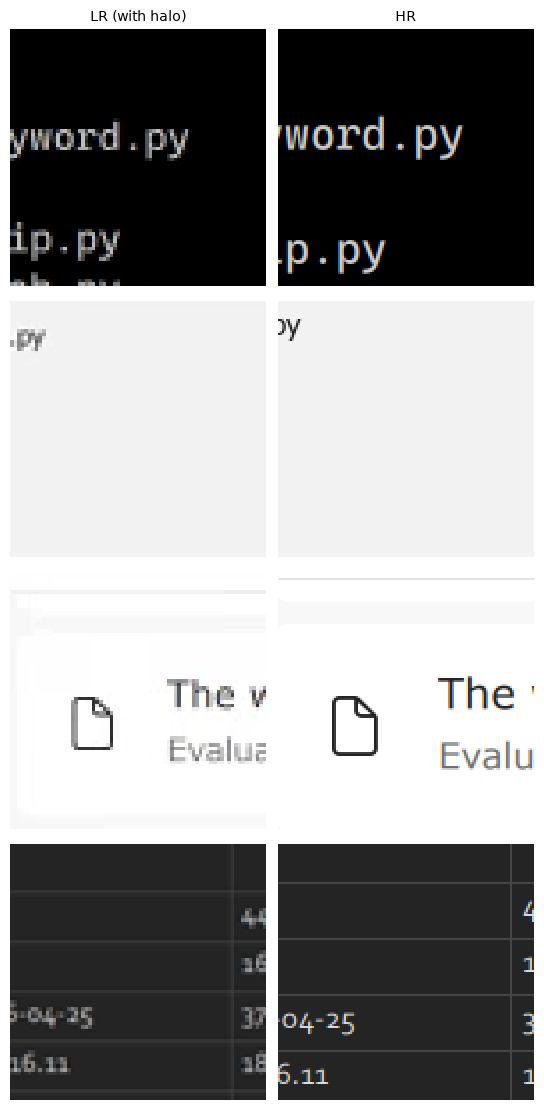

In [3]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE, val_batch_size=128)
trim = training.trimmer(manifest)
val_sources = manifest["splits"]["val"]["sources"]


def content(source):
    """What a source shows: a drawn desktop screen, a photo (as a moving clip) or a video."""
    if source["dataset"] == "screens":
        return "screen"
    return "photo" if "motion" in source else "video"


for split in ("train", "val"):
    counts = {}
    for source in manifest["splits"][split]["sources"]:
        first, end = source["patches"]
        counts[content(source)] = counts.get(content(source), 0) + end - first
    print(f"{split:<6}" + "  ".join(f"{name} {count:,}" for name, count in counts.items()))

shown = [source["patches"][0] for source in val_sources if content(source) == "screen"][::7][:4]
training.show_patches({"LR (with halo)": torch.stack([val_loader.dataset[i][0] for i in shown]),
                       "HR": torch.stack([val_loader.dataset[i][1] for i in shown])})

### How a validation patch is grouped

Every result is also split by what a patch shows (screen, photo, video), by the display
scale a screen was drawn at (100% is the smallest text), by bitrate and by downscale filter -
and by **what the host sends today**: every ffmpeg line of the host scales with swscale's
bicubic and encodes with x264 `ultrafast`, which has no loop filter. (Its Windows hardware
lines ask `scale_d3d11` for `w=`/`h=`, which the filter calls `width`/`height`, so a scaled
share falls through to that x264 line.)

In [4]:
screen_info = {row["file"]: row for row in json.loads((sources.RAW / "screens" / "screens.json").read_text())}


def bitrate(bpp):
    if bpp is None:
        return "no codec"
    return "bpp 0.2-0.3" if bpp < 0.3 else "bpp 0.3-0.5" if bpp < 0.5 else "bpp 0.5-1.0"


def labels(source):
    """The groups one source's patches are in."""
    made = source["degradation"]
    host_today = made["bpp"] is not None and all(made[key] == value for key, value in HOST_TODAY.items())
    out = {"content": content(source), "bitrate": bitrate(made["bpp"]), "filter": made["filter"],
           "host today": "yes" if host_today else "no"}
    if out["content"] == "screen":
        out["display scale"] = f"{screen_info[source['file']]['scale']:.0%}"
    return out


groups = {}   # way of grouping -> group -> the indices of its validation patches
for source in val_sources:
    first, end = source["patches"]
    for key, value in labels(source).items():
        groups.setdefault(key, {}).setdefault(value, []).extend(range(first, end))
for key, members in groups.items():
    print(f"{key:<14}" + "  ".join(f"{value} {len(indices)}" for value, indices in sorted(members.items())))

content       photo 784  screen 1154  video 1585
bitrate       bpp 0.2-0.3 831  bpp 0.3-0.5 1080  bpp 0.5-1.0 1276  no codec 336
filter        area 1027  bicubic 1304  bilinear 1192
host today    no 2787  yes 736
display scale 100% 303  125% 278  150% 387  200% 186


### What a model is told

`degrade.condition` turns how a source was made into numbers: for `bpp`, log2 of its bitrate
against the host's default (0.46) and a 1 for no codec; for `path`, the filter one-hot and a 1
for the loop filter. The told model gets them as a second input, one per patch, the same
for the whole patch, from loaders of their own.

In [5]:
def told_condition(source):
    return degrade.condition(source["degradation"], TOLD)


for source in val_sources[:3]:
    made = source["degradation"]
    print(f"{made['filter']:<9} bpp {made['bpp'] if made['bpp'] is None else round(made['bpp'], 3)!s:<6} "
          f"loop filter {made['deblock']!s:<6} -> {np.round(told_condition(source), 2).tolist()}")

told_train_loader, told_val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE, val_batch_size=128,
                                                      condition=told_condition)

area      bpp 0.239  loop filter True   -> [-0.9399999976158142, 0.0, 0.0, 0.0, 1.0, 1.0]
bicubic   bpp 0.267  loop filter True   -> [-0.7799999713897705, 0.0, 0.0, 1.0, 0.0, 1.0]
bilinear  bpp 0.623  loop filter True   -> [0.4399999976158142, 0.0, 1.0, 0.0, 0.0, 1.0]
train  17140 patches from 1089 sources
val     3523 patches from 225 sources


## 2. Model

Notebook 7's body: a 3x3 stem to 24 channels, two residual blocks, a 3x3 tail that makes one
brightness correction per output pixel, added to R, G and B alike over the bicubic skip.

The told model is the same body with one addition: a 1x1 convolution turns the condition
into a **shift per channel**, added after the stem and inside each residual block, before
its ReLU. It starts at zero, so untrained it is the blind model.

    condition --> 1x1 conv --> + (after the stem)
              --> 1x1 conv --> + (in block 1)      every shift is one number per channel
              --> 1x1 conv --> + (in block 2)

**It ships as the blind graph.** For one stream the condition does not change, so each shift
is a constant per channel, and a constant added after a convolution is that convolution's
bias. `baked(condition)` folds the shifts into the biases and returns a plain
`models.LumaUpscaler`: one input, the client's contract unchanged, the cost unchanged, and
one graph per bitrate.

In [6]:
class ToldLuma(models.Upscaler):
    """`models.LumaUpscaler` given a condition (N, K, 1, 1) as a second input, which shifts
    each channel after the stem and inside each residual block."""

    def __init__(self, conditions, width=WIDTH, blocks=BLOCKS, stem=STEM, skip=5, scale=2):
        super().__init__(scale, skip)
        self.width, self.blocks, self.stem = width, blocks, stem
        # the same layers as LumaUpscaler((width,), blocks, stem), in the same order, so the
        # same seed starts both alike and `baked` can copy them across
        self.body = nn.Sequential(nn.Conv2d(3, width, stem, padding=stem // 2), nn.ReLU(inplace=True),
                                  *[models.ResidualBlock(width) for _ in range(blocks)])
        self.tail = models.zero_start(nn.Conv2d(width, scale * scale, 3, padding=1))
        self.halo = self.halo_for(stem, blocks + 1)
        self.shifts = nn.ModuleList([nn.Conv2d(conditions, width, 1, bias=False) for _ in range(blocks + 1)])
        for shift in self.shifts:
            nn.init.zeros_(shift.weight)   # untrained, the condition changes nothing

    def residual(self, x, condition):
        h = torch.relu(self.body[0](x) + self.shifts[0](condition))
        for block, shift in zip(self.body[2:], self.shifts[1:]):
            h = h + block.point(torch.relu(block.conv(h) + shift(condition)))
        luma = self.tail(h)
        return torch.cat([luma, luma, luma], dim=1)

    def forward(self, x, condition):
        return self.shuffle(self.skip(x) + self.residual(x, condition))

    @torch.no_grad()
    def baked(self, condition):
        """The same model for one condition, as a plain LumaUpscaler: each shift folded into
        the bias of the convolution it follows."""
        device = next(self.parameters()).device
        plain = models.LumaUpscaler((self.width,), self.blocks, self.stem, self.skip_size, self.scale).to(device)
        plain.load_state_dict({k: v for k, v in self.state_dict().items() if not k.startswith("shifts.")})
        c = torch.as_tensor(np.asarray(condition), dtype=torch.float32, device=device).reshape(1, -1, 1, 1)
        convs = [plain.body[0], *[block.conv for block in plain.body[2:]]]
        for conv, shift in zip(convs, self.shifts):
            conv.bias += shift(c).flatten()
        return plain.eval()


CONDITIONS = sum(degrade.CONDITIONS[part] for part in TOLD)   # numbers the told model is given


def build(told=False):
    """A fresh model: blind, or told `TOLD`."""
    if told:
        return ToldLuma(CONDITIONS, scale=SCALE).to(DEVICE)
    return models.LumaUpscaler((WIDTH,), BLOCKS, STEM, scale=SCALE).to(DEVICE)

In [7]:
"""Checks: both start as bicubic, and baking a condition into the plain model is exact."""

models.check_skip_is_bicubic(SCALE)
blind, told_model = build(), build(told=True)
assert blind.halo == told_model.halo <= manifest["halo"], "the model reaches further than the patches' halo"
print(f"blind: {models.count_parameters(blind, True):,} learned parameters, told: {models.count_parameters(told_model, True):,}, "
      f"halo {told_model.halo}")

lr_probe = next(iter(val_loader))[0][:8].to(DEVICE)
with torch.no_grad(), training.full_precision():
    bicubic = trim(models.bicubic(lr_probe, SCALE))
    for name, out in (("blind", blind(lr_probe)), ("told", told_model(lr_probe, torch.randn(8, CONDITIONS, 1, 1, device=DEVICE)))):
        gap = (trim(out) - bicubic).abs().max().item()
        assert gap < 1e-5, f"untrained {name} is not bicubic ({gap:.1e})"

    # random weights everywhere, then one condition baked in
    for weight in told_model.parameters():
        if weight.requires_grad:
            weight.normal_(0, 0.1)
    c = torch.randn(1, CONDITIONS, 1, 1, device=DEVICE)
    x = torch.rand(2, 3, 40, 40, device=DEVICE)
    gap = (told_model(x, c.expand(2, -1, -1, -1)) - told_model.baked(c.cpu().numpy())(x)).abs().max().item()
assert gap < 1e-5, f"the baked model computes something else ({gap:.1e})"
print(f"a told model and the plain model baked from it differ by {gap:.1e} (float32 rounding)")

blind: 13,156 learned parameters, told: 13,588, halo 4
a told model and the plain model baked from it differ by 4.8e-07 (float32 rounding)


## 3. Speed

What ships is a `models.LumaUpscaler` either way - the blind graph, or one baked from the
told model - so the speed is notebook 7's, counted again at the client's tile (as in
notebooks 3 and 4: operations and memory traffic in the ONNX graph, and the roofline
estimate at the share of its peak this computer's GPU reaches).

In [8]:
plan = tiles.plan_tiling((FRAME_WIDTH, FRAME_HEIGHT), scale=SCALE, halo=blind.halo)
tile_shape = plan["input"][2:]   # (height, width) of one tile, halo included
graph = webexport.export(blind, "speed_check_screens.onnx", tile_shape, halo=blind.halo,
                         models_dir=training.CHECKPOINT_DIR / "speed")
assert not graph["outside_budget"], graph["outside_budget"]
work = webexport.count_work(graph["path"])
ops_per_pixel = work["operations"] / work["input_pixels"]
bytes_per_pixel = work["activation_bytes"] / work["input_pixels"]


def frame_work(pixels, runs):
    """Operations and bytes for `pixels` LR pixels, computed in `runs` runs of the graph."""
    return {"operations": pixels * ops_per_pixel, "bytes": pixels * bytes_per_pixel + runs * work["weight_bytes"]}


frame_lr = torch.rand(1, 3, FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, device=DEVICE)
with torch.no_grad():
    measured_ms = speed.time_ms(lambda: blind.eval()(frame_lr), seconds=1.0)
whole_frame = frame_work(frame_lr.shape[2] * frame_lr.shape[3], runs=1)
efficiency = speed.roofline_ms(whole_frame, *speed.HARDWARE[speed.THIS_GPU])[0] / measured_ms if DEVICE.type == "cuda" else 1.0
print(f"{ops_per_pixel:,.0f} operations and {bytes_per_pixel:,.0f} bytes per LR pixel; "
      f"{measured_ms:.2f} ms a 1080p frame measured here ({efficiency:.0%} of the peak)")

tiled = frame_work(plan["runs"] * tile_shape[0] * tile_shape[1], plan["runs"])
for short, device in ESTIMATE_ON.items():
    ms, limit = speed.roofline_ms(tiled, *speed.HARDWARE[device])
    print(f"  {short:<10}{ms / efficiency:6.1f} ms a 1080p frame ({limit}-bound), {speed.frame_budget(ms / efficiency)}")

28,120 operations and 2,536 bytes per LR pixel; 3.21 ms a 1080p frame measured here (44% of the peak)
  Iris Xe     47.4 ms a 1080p frame (memory-bound), under 30 fps
  GTX 1650    25.2 ms a 1080p frame (memory-bound), 30 fps
  RTX 3060     8.9 ms a 1080p frame (memory-bound), 60 fps


## 4. Train

The recipe of notebooks 2, 3, 4 and 7: Adam from 1e-3, batch 32, `metrics.ssim_l1_loss`, the
epoch with the best luma SSIM kept, each run trained until it has converged. The blind model
three times (seeds 0, 1, 2), the told model once, at seed 0.

**The told model and the blind one at the same seed differ in one thing only.** They start
from the same weights - the shifts start at zero - and see the same batches in the same
order, so the gap between them is what the condition buys, with none of a re-draw's luck in
it. The three blind seeds still say how large luck is.

Each run saves its training to `checkpoints/screens_runs/` after every epoch: run the cell
again after an interruption and it carries on; finished runs just load.

In [9]:
def train(name, told=False, seed=0):
    """Train a fresh model, or load its saved training. Returns it at its best epoch, its
    history and its best epoch."""
    torch.manual_seed(seed)
    model = build(told)
    torch.manual_seed(seed)   # the same batches in the same order, told or not
    loaders = (told_train_loader, told_val_loader) if told else (train_loader, val_loader)
    run_file = RUN_DIR / ("_".join(name.split()) + f"_seed{seed}.pt")
    history, best = training.train(model, *loaders, trim, MAX_EPOCHS, learning_rate=LEARNING_RATE,
                                   loss_fn=metrics.ssim_l1_loss, select="ssim", checkpoint=run_file, verbose=0)
    print(f"{name:<28} seed {seed}: best epoch {best['epoch']:3} of {len(history):3}, ssim-y {best['score']:.4f}")
    return model, history, best


trained, histories, bests = {}, {}, {}
for seed in SEEDS:
    name = f"blind, seed {seed}"
    trained[name], histories[name], bests[name] = train("blind", seed=seed)
trained[TOLD_NAME], histories[TOLD_NAME], bests[TOLD_NAME] = train(TOLD_NAME, told=True, seed=SEEDS[0])

# notebook 4's winner: the same body, trained on the set before it had screens
before = training.load_checkpoint(BEFORE)
trained["before screens"] = getattr(models, before["architecture"])(scale=SCALE, **before["arguments"]).to(DEVICE)
trained["before screens"].load_state_dict(before["state_dict"])
print(f"before screens: notebook 4's {before['strategy']}, {before['epochs']} epochs, loaded")

blind                        seed 0: best epoch 125 of 137, ssim-y 0.9350
blind                        seed 1: best epoch 116 of 134, ssim-y 0.9349
blind                        seed 2: best epoch 126 of 132, ssim-y 0.9345
told the bitrate and path    seed 0: best epoch 116 of 128, ssim-y 0.9369
before screens: notebook 4's luma 24 + 2 blocks, 116 epochs, loaded


### The result

Every model on the whole validation set, against the mean of the blind model's three seeds.
**better** / **worse** means the gap is wider than the seeds' spread; **luck** means this set
cannot tell them apart.

In [10]:
def score(name, indices=None):
    """`metrics.report` of one model (or "bicubic") on the validation patches `indices` (None: all)."""
    dataset = (told_val_loader if name == TOLD_NAME else val_loader).dataset
    if indices is not None:
        dataset = Subset(dataset, indices)
    model = models.Resize(SCALE).to(DEVICE) if name == "bicubic" else trained[name]
    return training.evaluate(model, DataLoader(dataset, batch_size=128), trim)


results = {name: score(name) for name in ["bicubic", *trained]}
seeds = [results[f"blind, seed {seed}"] for seed in SEEDS]
spread = {key: max(s[key] for s in seeds) - min(s[key] for s in seeds) for key in ("ssim", "wpsnr")}
blind_mean = {key: float(np.mean([s[key] for s in seeds])) for key in ("ssim", "wpsnr")}


def verdict(name, scores):
    """The last column: ssim-y against the blind model's mean."""
    if name == "bicubic" or name.startswith("blind"):
        return ""
    gap = scores["ssim"] - blind_mean["ssim"]
    word = "luck" if abs(gap) <= spread["ssim"] else ("better" if gap > 0 else "worse")
    return f"{gap:+11.4f}  {word}"


print(f"the blind model at {len(SEEDS)} seeds: {spread['ssim']:.4f} ssim-y and {spread['wpsnr']:.2f} dB wpsnr apart; "
      f"last column: ssim-y against their mean of {blind_mean['ssim']:.4f}")
metrics.print_table(results, extra=verdict)
best_name = max((name for name in trained if name != "before screens"), key=lambda name: results[name]["ssim"])
print(f"\nbest: {best_name}")

the blind model at 3 seeds: 0.0005 ssim-y and 0.07 dB wpsnr apart; last column: ssim-y against their mean of 0.9348
                               wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                        34.14    33.18    50.67    51.46     32.02   0.9049
blind, seed 0                  35.51    34.63    50.71    51.50     33.12   0.9350
blind, seed 1                  35.57    34.70    50.71    51.49     33.18   0.9349
blind, seed 2                  35.52    34.64    50.71    51.49     33.14   0.9345
told the bitrate and path      35.79    34.94    50.72    51.50     33.35   0.9369    +0.0021  better
before screens                 35.33    34.45    50.70    51.49     32.96   0.9292    -0.0056  worse

best: told the bitrate and path


### By group

The gain over bicubic in each group: luma SSIM, and luma PSNR in dB. `blind` is the mean of
the three seeds, and its `±` is their spread in that group - the ruler for the columns
beside it. Whatever wins overall has to win on the **host today** row too, because it is
what a client receives; and 100% display scale is the smallest text, the hardest case.

In [11]:
SHOW = ["before screens", "blind", TOLD_NAME]


def gain(scores, base):
    return scores["ssim"] - base["ssim"], scores["y"] - base["y"]


for key in ("content", "display scale", "bitrate", "filter", "host today"):
    print(f"\n{key}: gain over bicubic, ssim-y / psnr-y dB")
    print(f"{'':<16}{'patches':>8}{'bicubic ssim-y':>16}" + "".join(f"{name:>30}" for name in SHOW))
    for value, indices in sorted(groups[key].items()):
        base = score("bicubic", indices)
        row = f"{value:<16}{len(indices):8}{base['ssim']:16.4f}"
        for name in SHOW:
            if name == "blind":
                ssim, y = zip(*(gain(score(f"blind, seed {seed}", indices), base) for seed in SEEDS))
                cell = f"{np.mean(ssim):+.4f}±{max(ssim) - min(ssim):.4f} / {np.mean(y):+.2f}"
            else:
                ssim, y = gain(score(name, indices), base)
                cell = f"{ssim:+.4f} / {y:+.2f}"
            row += f"{cell:>30}"
        print(row)


content: gain over bicubic, ssim-y / psnr-y dB
                 patches  bicubic ssim-y                before screens                         blind     told the bitrate and path
photo                784          0.8359               +0.0217 / +0.74        +0.0194±0.0005 / +0.46               +0.0238 / +0.73
screen              1154          0.8851               +0.0425 / +1.75        +0.0617±0.0012 / +2.99               +0.0626 / +3.06
video               1585          0.9535               +0.0122 / +1.20        +0.0120±0.0006 / +0.88               +0.0137 / +1.33

display scale: gain over bicubic, ssim-y / psnr-y dB
                 patches  bicubic ssim-y                before screens                         blind     told the bitrate and path
100%                 303          0.8504               +0.0521 / +1.17        +0.0817±0.0021 / +2.10               +0.0841 / +2.28
125%                 278          0.8712               +0.0446 / +1.23        +0.0676±0.0019 / +2.36            

### What it looks like

A held-out screen through the stream the way the host sends it today (swscale's bicubic,
x264 `ultrafast` without a loop filter, the host's default 0.46 bpp, a still screen after a
second), then upscaled whole: bicubic, the model trained before there were screens, and the
best one now.

                               wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                        26.90    25.67    43.13    42.49     25.61   0.9229
before screens                 27.75    26.54    43.14    42.50     26.42   0.9484
told the bitrate and path      28.44    27.23    43.14    42.49     27.08   0.9595
test/00018.png: ['code'], 100% display scale, dark theme


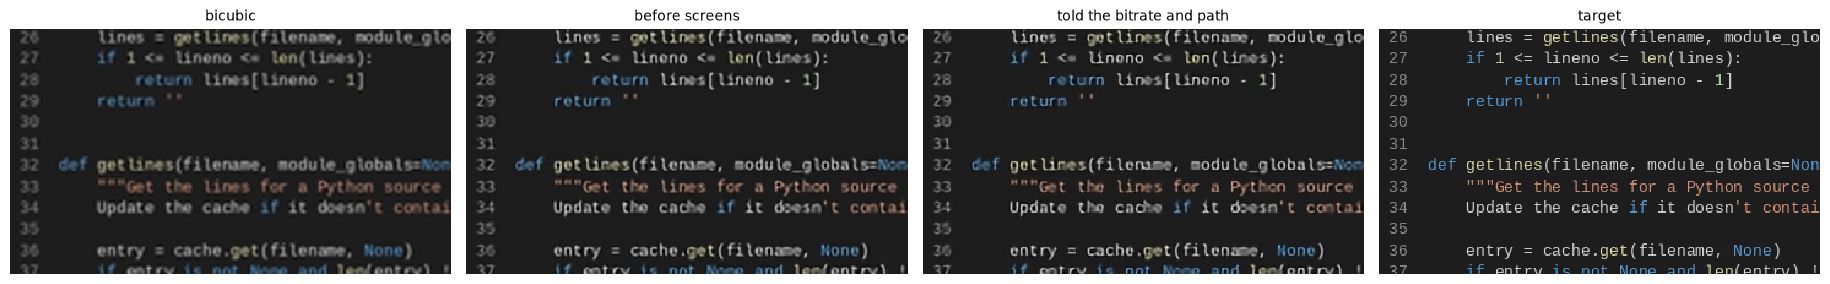

In [12]:
def shipped(name, bpp=degrade.STREAM_BPP):
    """A model as it ships for one stream from the host today: a told model baked for it."""
    if name != TOLD_NAME:
        return trained[name].eval()
    stream = degrade.Degradation(scale=SCALE, bpp=bpp, **HOST_TODAY)
    return trained[name].baked(degrade.condition(stream, TOLD))


@torch.no_grad()
def upscale(name, lr):
    """A whole frame through a model, its edge padded by repetition like a tiled client."""
    if name == "bicubic":
        return models.bicubic(lr, SCALE).clamp(0, 1)
    halo = blind.halo
    padded = F.pad(lr, (halo,) * 4, mode="replicate")
    return patches.trim(shipped(name)(padded), halo * SCALE).clamp(0, 1)


# a held-out screen at 100% or 125% (the smallest text), with code on it, or else a document
pick = min((row for row in screen_info.values() if row["split"] == "test" and row["scale"] <= 1.25),
           key=lambda row: {"code": 0, "document": 1}.get(row["apps"][0], 2))
picture = np.asarray(Image.open(sources.RAW / "screens" / pick["file"]).convert("RGB"))[:720, :1280]
host = degrade.Degradation(scale=SCALE, bpp=degrade.STREAM_BPP, **HOST_TODAY)
truth, lr_clip = degrade.degrade(np.repeat(picture[None], 30, axis=0), host)
target, lr = training.to_tensor(truth[-1]), training.to_tensor(lr_clip[-1])

pictures = {name: upscale(name, lr) for name in dict.fromkeys(["bicubic", "before screens", best_name])}
metrics.print_table({name: metrics.report(image, target) for name, image in pictures.items()})
Image.fromarray(training.to_image(pictures[best_name])).save(training.SAMPLE_DIR / "upscaled_screens.png")
print(f"{pick['file']}: {pick['apps']}, {pick['scale']:.0%} display scale, {pick['theme']} theme")

# show the busiest 200x360 of it: the most edges, which on a screen is the most text
edges = np.abs(np.diff(training.to_image(target).astype(np.float32).mean(axis=2), axis=1))
top, left = max(((y, x) for y in range(0, edges.shape[0] - 200, 20) for x in range(0, edges.shape[1] - 360, 20)),
                key=lambda corner: edges[corner[0]:corner[0] + 200, corner[1]:corner[1] + 360].mean())
box = (slice(top, top + 200), slice(left, left + 360))
panels = {**pictures, "target": target}
fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 3))
for ax, (name, image) in zip(axes, panels.items()):
    ax.imshow(training.to_image(image)[box], interpolation="nearest")
    ax.set_title(name, fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 5. Save and reload

The best model by luma SSIM is saved whole - a told model with what it is told - with
everything needed to rebuild it. We load it into a fresh model and check it computes the
same thing (a told model through the plain graph it bakes to for the host today).

In [13]:
best = trained[best_name]
if best_name == TOLD_NAME:
    architecture, arguments, told_parts = "ToldLuma", {"conditions": CONDITIONS, "width": WIDTH, "blocks": BLOCKS, "stem": STEM}, TOLD
else:
    architecture, arguments, told_parts = "LumaUpscaler", {"widths": (WIDTH,), "blocks": BLOCKS, "stem": STEM}, ()
training.save_checkpoint(CHECKPOINT, best, architecture=architecture, arguments=arguments, told=list(told_parts),
                         scale=SCALE, halo=best.halo, loss="ssim_l1_loss", select="ssim",
                         epochs=len(histories[best_name]), best_epoch=bests[best_name]["epoch"],
                         val=results[best_name], val_bicubic=results["bicubic"], blind_mean=blind_mean,
                         seed_spread=spread, host_today=HOST_TODAY, degradation=manifest["degradation"])

# rebuild it from the file alone, the way a later notebook would
checkpoint = training.load_checkpoint(CHECKPOINT)
model_class = ToldLuma if checkpoint["architecture"] == "ToldLuma" else models.LumaUpscaler
loaded = model_class(scale=checkpoint["scale"], **checkpoint["arguments"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
if checkpoint["told"]:
    condition = degrade.condition(host, tuple(checkpoint["told"]))
    training.assert_same_model(best.baked(condition), loaded.baked(condition))
else:
    training.assert_same_model(best, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_screens.pt (65 KB)
reloaded model is identical


## 6. Export for the browser

At the client's tile (a 320x180 step): float32 and float16, and float16 as a whole 1080p
frame. A told model is exported **baked**: one plain graph per bitrate in `BAKE_BPP`, each
for the host's path today - one input, the client's contract unchanged. The whole-frame
graph is the host's default bitrate.

In [14]:
def input_shape(step_height, step_width, halo):
    """The model input for a step: the step plus the halo on every side, as (height, width)."""
    return (step_height + 2 * halo, step_width + 2 * halo)


def check_and_time(info, module, shape, dtype, tolerance):
    """Check a written graph against the torch module, time it on the CPU, print one line."""
    webexport.check_graph(info["path"], module, np.random.rand(1, 3, *shape).astype(np.float32), dtype, tolerance)
    ms = webexport.time_graph(info["path"], shape, dtype)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))


tile_name = f"tile{STEP_WIDTH}x{STEP_HEIGHT}"
halo = best.halo
tile_shape = input_shape(STEP_HEIGHT, STEP_WIDTH, halo)
frame_shape = input_shape(FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, halo)
if best_name == TOLD_NAME:
    graphs = {f"_bpp{bpp:g}": shipped(best_name, bpp) for bpp in BAKE_BPP}   # file suffix -> plain model
else:
    graphs = {"": shipped(best_name)}

for suffix, module in graphs.items():
    file, label = f"upscale_{NAME}{suffix}", f"{NAME}{suffix.replace('_', ' ')}"
    fp32 = webexport.export(module, f"{file}_{tile_name}.onnx", tile_shape, label=f"{label} fp32", halo=halo)
    check_and_time(fp32, module, tile_shape, np.float32, tolerance=2e-3)

    fp16 = webexport.to_float16(fp32, f"{file}_fp16_{tile_name}.onnx")
    webexport.write_metadata(fp16["path"], {"label": f"{label} fp16"})
    check_and_time(fp16, module, tile_shape, np.float16, tolerance=4e-3)

    if suffix in ("", f"_bpp{degrade.STREAM_BPP:g}"):
        frame = webexport.to_frame(fp16, f"{file}_fp16_{tile_name}_frame.onnx", FRAME_WIDTH, FRAME_HEIGHT)
        check_and_time(frame, module, frame_shape, np.float16, tolerance=4e-3)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_screens_24x2_bpp0.2_tile320x180.onnx           57.6 KB    4.09 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_screens_24x2_bpp0.2_fp16_tile320x180.onnx      31.0 KB    4.23 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_screens_24x2_bpp0.46_tile320x180.onnx          57.6 KB    4.11 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_screens_24x2_bpp0.46_fp16_tile320x180.onnx     31.0 KB    3.87 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_screens_24x2_bpp0.46_fp16_tile320x180_frame.onnx   31.0 KB   49.72 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_screens_24x2_bpp1_tile320x180.onnx             57.6 KB    4.08 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_screens_24x2_bpp1_fp16_tile320x180.onnx        31.0 KB    4.05 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
compare in a browser: uv run src/upscale/benchmark/main.py
